# Finite differences

This notebook explores finite difference methods for approximating the derivative of a function or signal.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

## Discretized functions

All the functions we evaluate with code are discretized when we represent them with numbers.
In this notebook, we'll look at some polynomial functions with intentionally coarse discriteizations.
Making the spacings between points smaller reduces error, but takes more time.
Often, we may be taking the derivative of a signal from recorded data and not have the option to get a smaller spacing between data points.

Text(0, 0.5, 'y')

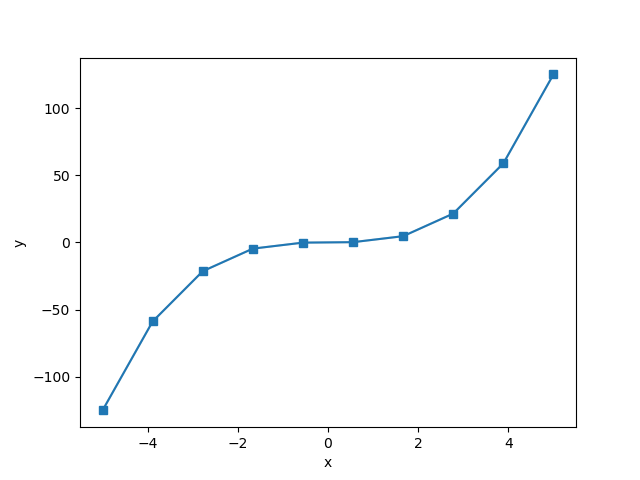

In [18]:
def y_func(x):
    return x**3

samples = 10
x = np.linspace(-5,5, samples)
x_fine = np.linspace(-5,5, 10)
y = y_func(x)

fig, ax = plt.subplots()
ax.plot(x_fine, y_func(x_fine), color="lightgray")
ax.plot(x, y,"s-")
ax.set_xlabel("x")
ax.set_ylabel("y")

## Forward difference

The slope from each sample to the next. With slicing it is one line, and the result has one fewer element than `y`: there is no "next" sample after the last one. The estimate belongs to the *left* point of each pair.

$$\frac{dy}{dx}\Big|_{x_i} \approx \frac{y_{i+1} - y_i}{x_{i+1} - x_i}$$

## Central difference

Use the samples on both sides and the slope belongs to the point in the middle. Two elements are lost, one at each end, and the estimate is much better: the errors of the two one-sided slopes cancel to first order.

$$\frac{dy}{dx}\Big|_{x_i} \approx \frac{y_{i+1} - y_{i-1}}{x_{i+1} - x_{i-1}}$$

## Backward difference

The same thing as the forward difference method, but backward!

$$\frac{dy}{dx}\Big|_{x_i} \approx \frac{y_{i} - y_{i-1}}{x_{i} - x_{i-1}}$$

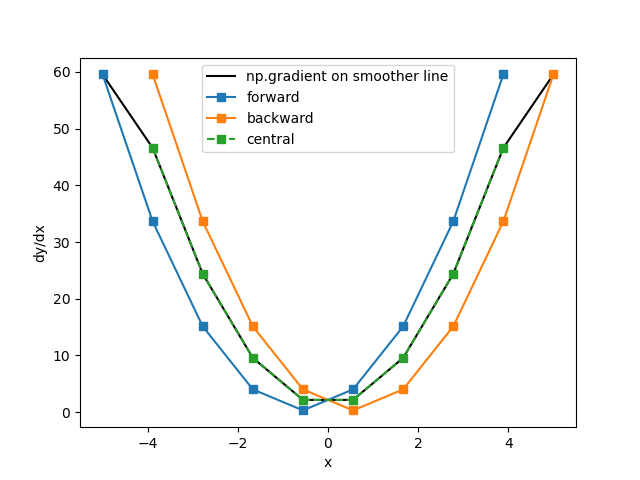

In [21]:
# Start with forward finite difference
def ffd(y, x):
    # assumes y and x are arrays of the same length
    dydx = (y[1:] - y[:-1]) / (x[1:] - x[:-1])
    return dydx, x[:-1]

def bfd(y, x):
    # assumes y and x are arrays of the same length
    dydx = (y[1:] - y[:-1]) / (x[1:] - x[:-1])
    return dydx, x[1:]

def cfd(y, x):
    # assumes y and x are arrays of the same length
    dydx = (y[2:] - y[:-2]) / (x[2:] - x[:-2])
    return dydx, x[1:-1]

fig, ax = plt.subplots()
ax.plot(x_fine, np.gradient(y_func(x_fine),x_fine), color="black", label="np.gradient on smoother line")

dyf, xf = ffd(y, x)
ax.plot(xf, dyf,"s-", label="forward")

dyb, xb = bfd(y, x)
ax.plot(xb, dyb,"s-", label="backward")

dyc, xc = cfd(y, x)
ax.plot(xc, dyc,"s--", label="central")

ax.set_xlabel("x")
ax.set_ylabel("dy/dx")
ax.legend()